# 6. External validation

Data the models never saw: measured hot-rolled structural members, a second compilation of the same
grades, specification-level values of normalised EN/ASTM grades, and measured values from 52 open-access
papers (rows flagged as suspect during transcription are left out).

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3g}")
R = ROOT / "results"; FIG = ROOT / "figures"
def fig(name, width=1000):
    display(Image(filename=str(FIG / f"{name}.png"), width=width))

In [2]:
pd.read_csv(R / "s06_structural_metrics.csv").round(2)

,subset,target,n,RMSE,MAE,bias,MAPE_pct,R2,spearman,coverage_90
0,all,YS_MPa,165,92.4,81.5,-77.5,20.1,-3.19,-0.3,0.3
1,all,UTS_MPa,165,68.4,61.2,-60.4,11.6,-3.36,0.37,0.47
2,all,El_pct,165,2.96,2.23,0.35,6.64,0.08,0.27,0.84
3,not microalloyed,YS_MPa,96,81.8,67.1,-60.1,16.8,-1.65,-0.37,0.49
4,not microalloyed,UTS_MPa,96,58.8,49.8,-48.5,9.61,-2.23,0.27,0.61
5,not microalloyed,El_pct,96,2.94,2.28,-0.01,6.54,0.09,0.23,0.82
6,microalloyed (Nb/V/Ti),YS_MPa,69,105,102,-102,24.6,-18.9,-0.08,0.04
7,microalloyed (Nb/V/Ti),UTS_MPa,69,79.9,77.1,-77.1,14.3,-11.7,0.59,0.28
8,microalloyed (Nb/V/Ti),El_pct,69,3,2.15,0.84,6.77,-0.05,0.22,0.87
9,all,Charpy energy at 0 C vs predicted ITT (Pickering),147,NaN,NaN,NaN,NaN,NaN,-0.25,NaN


Strength of modern as-rolled sections is under-predicted by ~50-70 MPa: they are finer-grained (and in
part microalloyed) compared with the handbook's bars. Stage 7 shows that a handful of measured members
removes this bias.

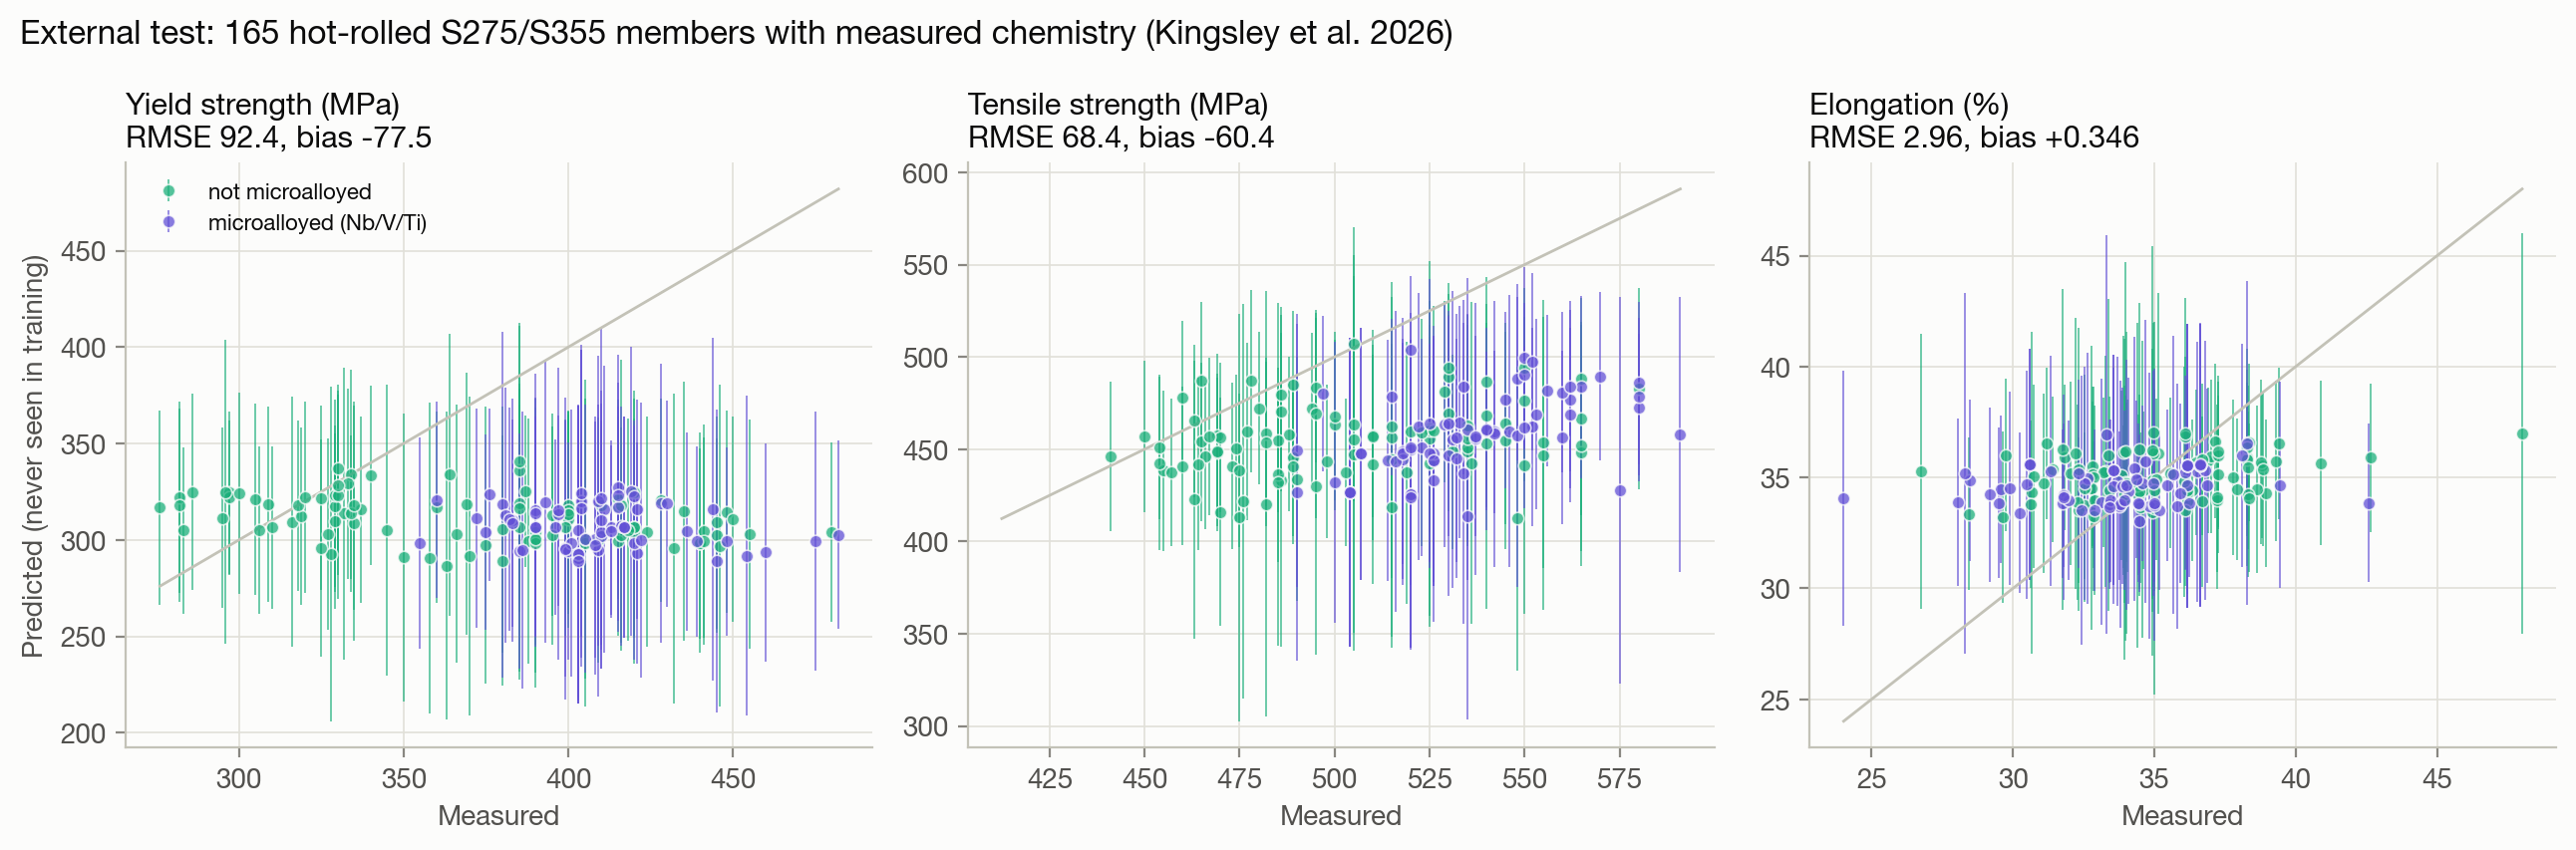

In [3]:
fig("fig20_external_structural")

In [4]:
pd.read_csv(R / "s06_other_checks.csv").round(3)

,check,target,n,RMSE,MAE,bias,R2,MAPE_pct,fraction_satisfied
0,independent typical values (annealed/normalized),UTS_MPa,3,18.1,17.6,-17.6,0.161,3.9,NaN
1,independent typical values (annealed/normalized),YS_MPa,3,12.7,12.2,-12.2,0.54,3.6,NaN
2,independent typical values (annealed/normalized),El_pct,3,0.876,0.756,-0.025,0.803,2.08,NaN
3,independent typical values (annealed/normalized),HB,3,9.21,7.05,-7.05,-0.711,5.16,NaN
4,SAE J1397 hot-rolled minimum <= predicted typical,UTS_MPa,35,NaN,NaN,NaN,NaN,NaN,1
5,SAE J1397 hot-rolled minimum <= predicted typical,YS_MPa,35,NaN,NaN,NaN,NaN,NaN,1
6,EN/ASTM/GB normalised grades (specification-le...,UTS,40,71.8,55,-20.8,0.44,10.9,NaN
7,EN/ASTM/GB normalised grades (specification-le...,YS,40,64.6,55.1,43.7,-0.086,22,NaN
8,EN/ASTM/GB normalised grades (specification-le...,El,40,10.8,10.4,10.4,-10.1,43.8,NaN


In [5]:
pd.read_csv(R / "s06_literature_metrics.csv").round(2)

,quantity,n,MAE,RMSE,bias,observed_mean,observed_sd,sources,count,max_excess_points,predicted_mean
0,pearlite fraction (%) - best estimate,13,7.58,8.8,4.61,NaN,NaN,NaN,NaN,NaN,NaN
1,pearlite fraction (%) - raw kinetic model,13,12.5,17.4,7.88,NaN,NaN,NaN,NaN,NaN,NaN
2,pearlite fraction (%) - lever rule baseline,13,7.58,8.8,4.61,NaN,NaN,NaN,NaN,NaN,NaN
3,ferrite grain size (µm),17,14.4,20.8,-4.6,NaN,NaN,NaN,NaN,NaN,NaN
4,pearlite spacing (nm),5,51.1,55.4,-29.5,NaN,NaN,NaN,NaN,NaN,NaN
5,yield strength (MPa),38,28.3,40.6,21.8,NaN,NaN,NaN,NaN,NaN,NaN
6,tensile strength (MPa),40,55,67.7,-25.9,NaN,NaN,NaN,NaN,NaN,NaN
7,"total elongation (%), as tested (gauge lengths...",34,4.37,5.67,1.64,NaN,NaN,NaN,NaN,NaN,NaN
8,"total elongation (%), converted to the handboo...",7,7.68,9.05,-7.68,NaN,NaN,NaN,NaN,NaN,NaN
9,"hardness (HB, HV x 0.95)",37,30.4,44.5,21.3,NaN,NaN,NaN,NaN,NaN,NaN


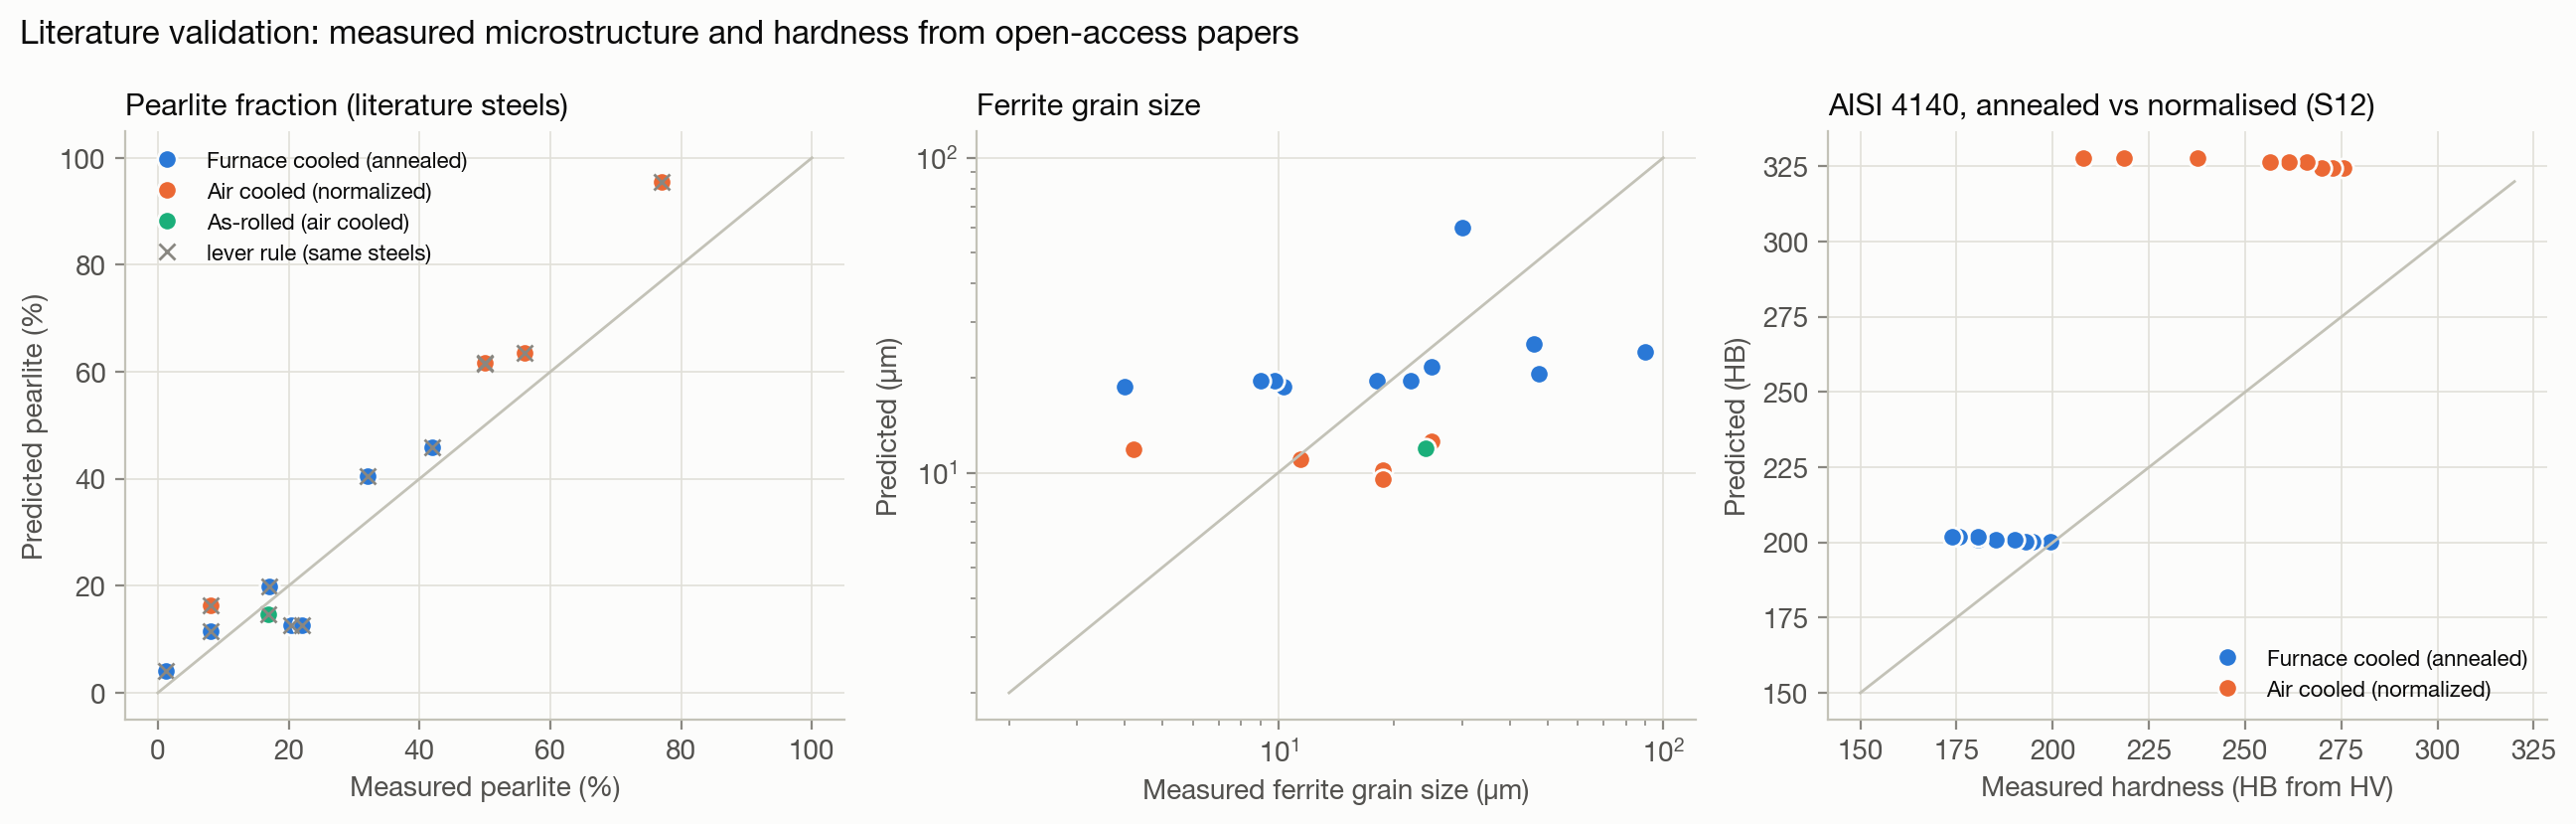

In [6]:
fig("fig21_literature_validation")

## The same steel after both routes
Papers that tested one heat furnace cooled and air cooled. The direction of the change is right; for the
alloy steels the predicted hardening is larger than measured, the same over-hardenability that the Jominy
bands show (notebook 8).

In [7]:
pd.read_csv(R / "s06_literature_paired_routes.csv").round(1)

,source_id,steel,target,measured_FC,measured_AC,measured_change,predicted_FC,predicted_AC,predicted_change
0,S12,"AISI 4140 (900 C, 1 h)",HB,200,276,76,200,325,124
1,S41,42CrMo4 (845FC),HB,174,286,112,186,287,101
2,S48,SAE 8620 (annealed),HB,151,179,27.7,144,174,29.7


## A dilatometer steel at stated cooling rates (23MnNiCrMo5-3)

In [8]:
pd.read_csv(R / "s06_continuous_cooling_hardness.csv").round(1)

,source_id,steel,rate_K_s,T_aust_C,HB_measured,HB_pred,HB_lo90,HB_hi90,B_pred,M_pred,microstructure_in_data
0,S51,"23MnNiCrMo5-3 (CCT, TA 880 C, 0.2 C/s)",0.2,880,212,154,108,200,0,0,True
1,S51,"23MnNiCrMo5-3 (CCT, TA 880 C, 1.0 C/s)",1,880,245,226,198,253,0.7,0,True
2,S51,"23MnNiCrMo5-3 (CCT, TA 880 C, 1.7 C/s)",1.7,880,254,238,203,274,0.9,0,True
3,S51,"23MnNiCrMo5-3 (CCT, TA 880 C, 3.0 C/s)",3,880,279,253,210,296,1,0,True
4,S51,"23MnNiCrMo5-3 (CCT, TA 880 C, 5.0 C/s)",5,880,330,267,220,314,0.9,0,True
5,S51,"23MnNiCrMo5-3 (CCT, TA 880 C, 25 C/s)",25,880,448,373,240,506,0.1,0.9,True
6,S51,"23MnNiCrMo5-3 (CCT, TA 880 C, 35 C/s)",35,880,454,379,240,517,0,0.9,True
7,S51,"23MnNiCrMo5-3 (CCT, TA 880 C, 100 C/s)",100,880,475,391,244,538,0,1,True
8,S51,"23MnNiCrMo5-3 (CCT, TA 830 C, 0.2 C/s)",0.2,830,218,156,111,202,0,0,True
9,S51,"23MnNiCrMo5-3 (CCT, TA 830 C, 1.0 C/s)",1,830,247,224,196,252,0.7,0,True


## Micrographs of the same steels, annealed and normalised
Published micrographs (CC BY 4.0) of SAE 1045 and SAE 4140 after furnace cooling and after still-air cooling,
with the model's prediction for that composition, temperature and bar diameter underneath. The normalised
4140 has the acicular structure of the bainite the model predicts (the authors describe Widmanstätten
ferrite and fine pearlite; calling it bainite is our reading).

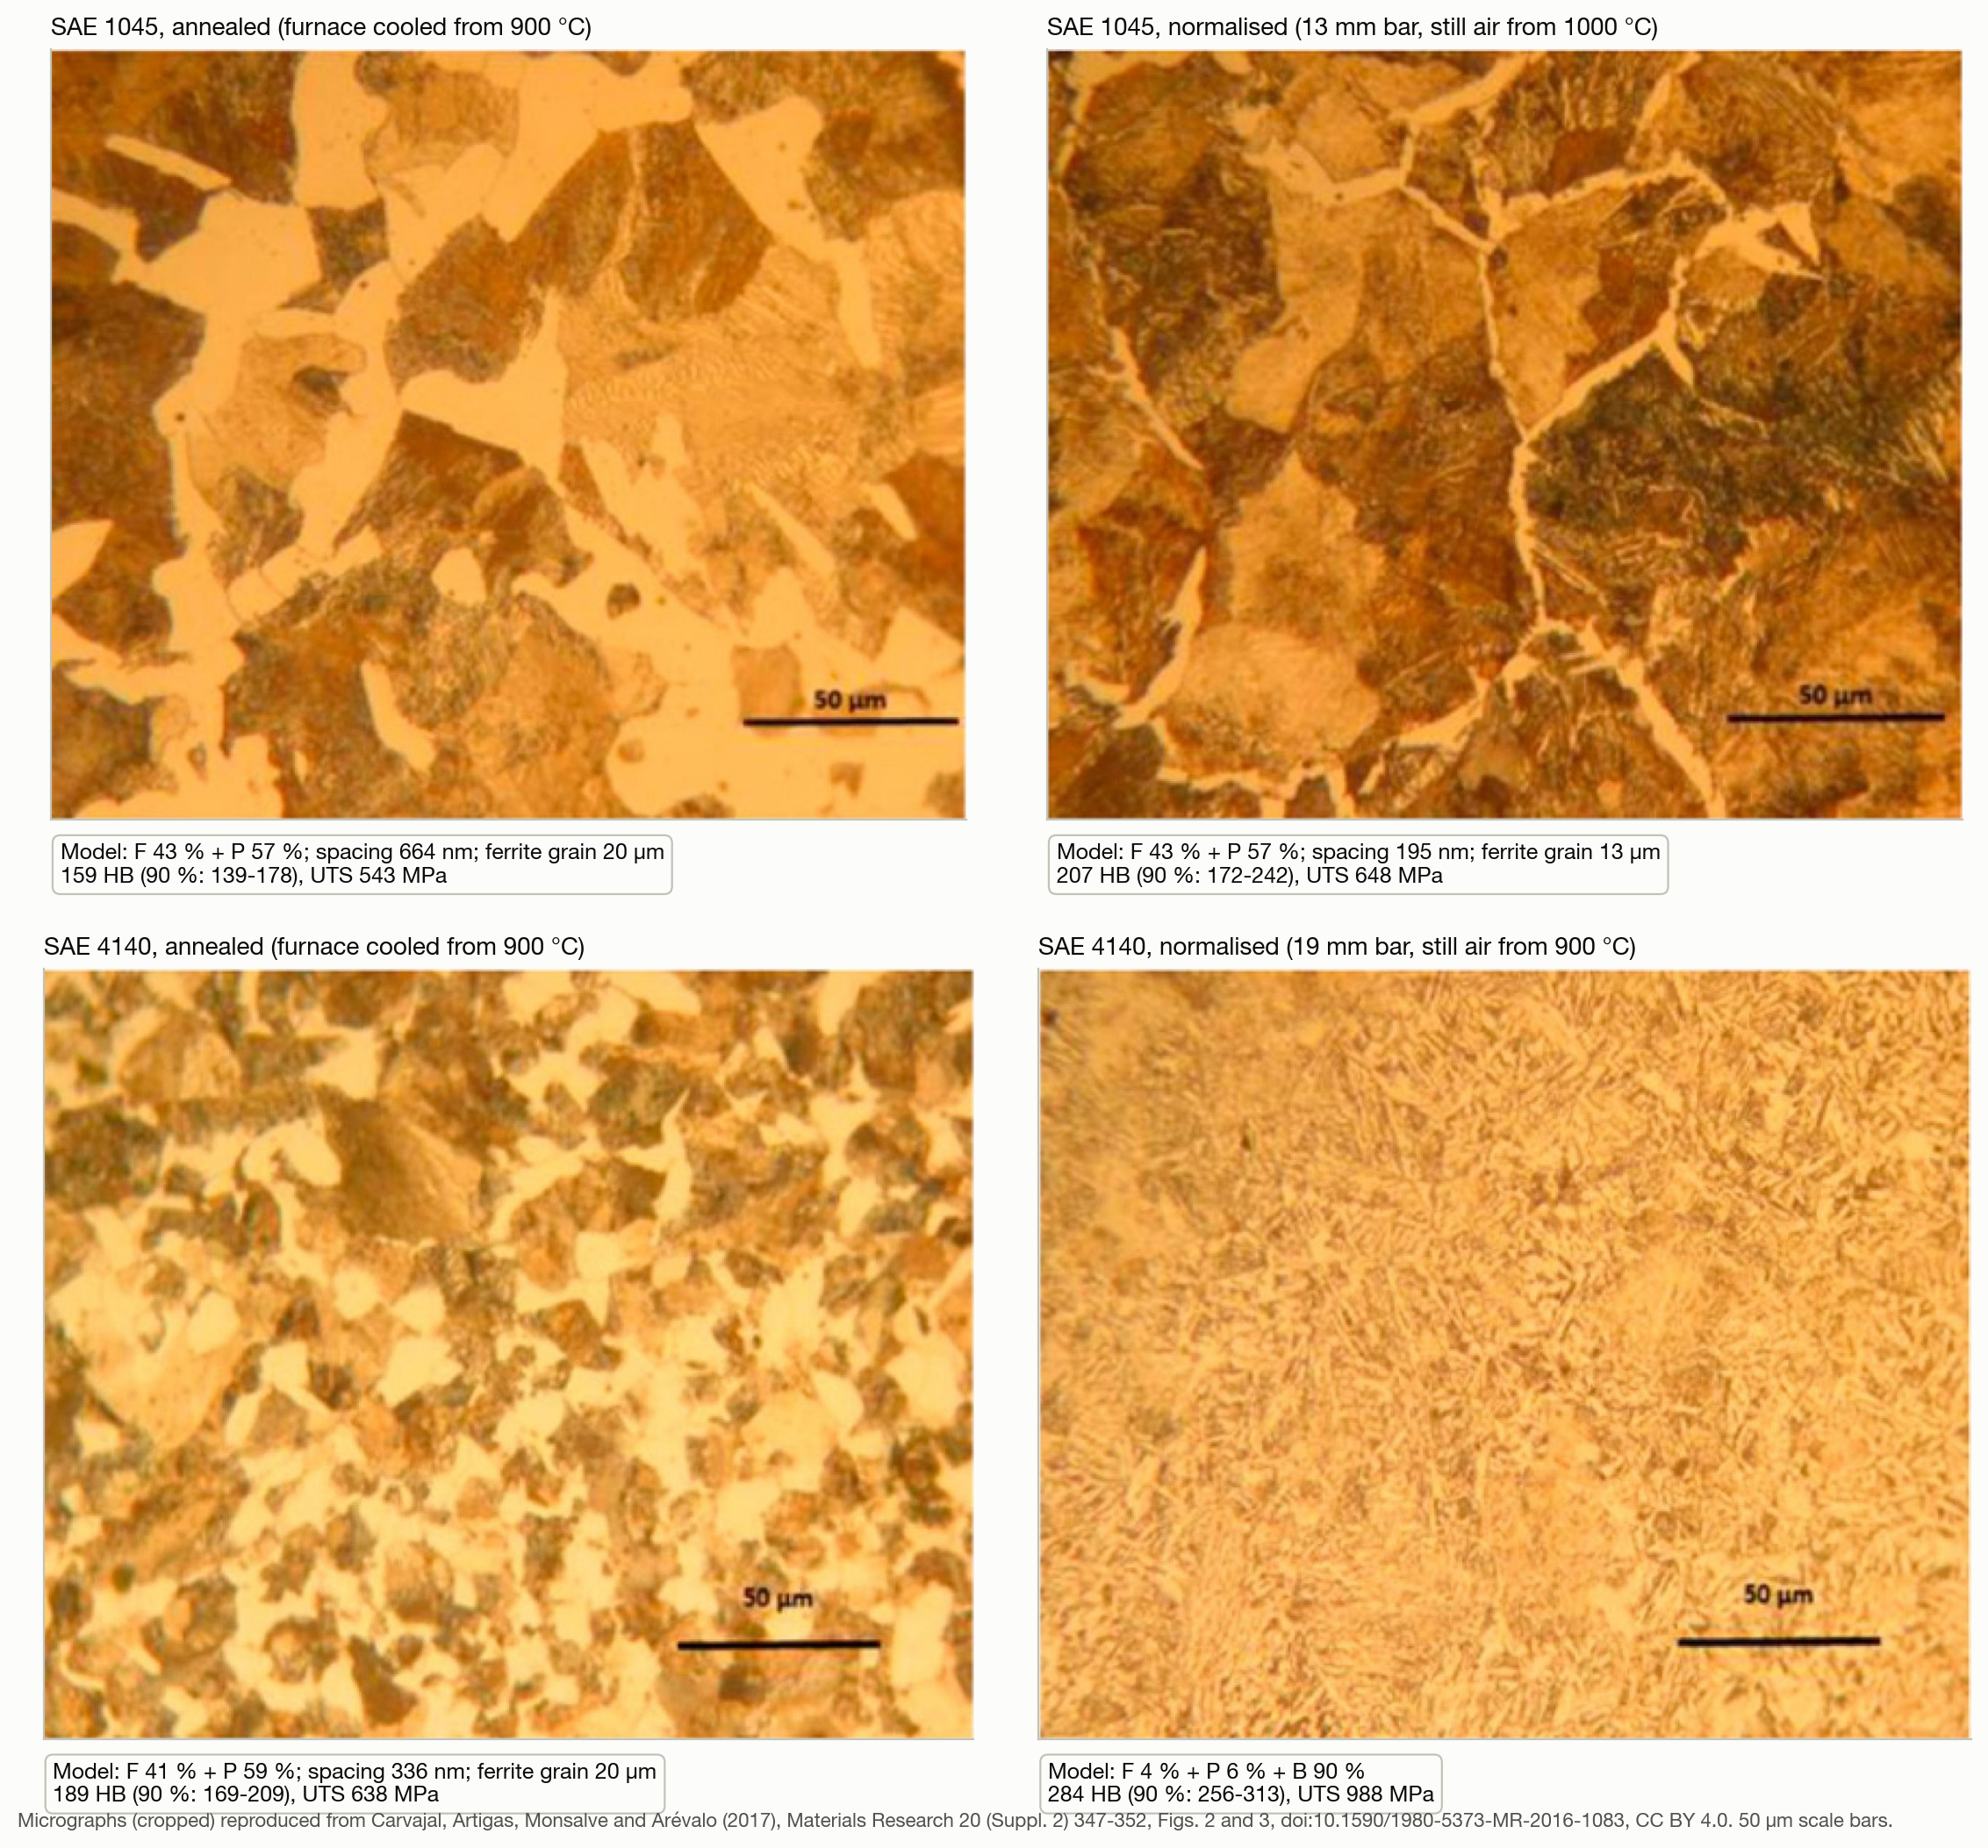

In [9]:
fig("fig30_micrographs_vs_model", 950)